In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [49]:
df_train = pd.read_csv('data_train.csv')
df_val = pd.read_csv('data_validation.csv')
df_test = pd.read_csv('data_test.csv')
df_prep = pd.read_csv('data_prepped.csv')

y_train = np.loadtxt('y_train.csv')
y_val = np.loadtxt('y_val.csv')
y_test = np.loadtxt('y_test.csv')

In [62]:
len(df_train)

7150

In [63]:
#only pick the numeric fields and pu tinto numpy array
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']
X_train = df_train[base].values
X_train

array([[ 287.,    6.,   23.,   16., 5657.],
       [ 365.,    6.,   21.,   15., 5657.],
       [ 287.,    6.,   22.,   16., 5657.],
       ...,
       [ 300.,    6.,   23.,   16.,  204.],
       [ 300.,    6.,   23.,   16.,  204.],
       [ 221.,    6.,   26.,   17.,   61.]], shape=(7150, 5))

In [64]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

The following will produce NaN in the matrix because some value in the feature matrix X_train are NULL

In [65]:
w0, w = train_linear_regression(X_train, y_train)
w0, w

(np.float64(nan), array([nan, nan, nan, nan, nan]))

In [66]:
X_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(X_train, y_train)
w0

np.float64(7.449451754828602)

In [67]:
y_pred = w0+X_train.dot(w)
y_pred

array([10.29578355, 10.92129839, 10.24584497, ..., 10.47719754,
       10.47719754,  9.89414506], shape=(7150,))

<Axes: ylabel='Count'>

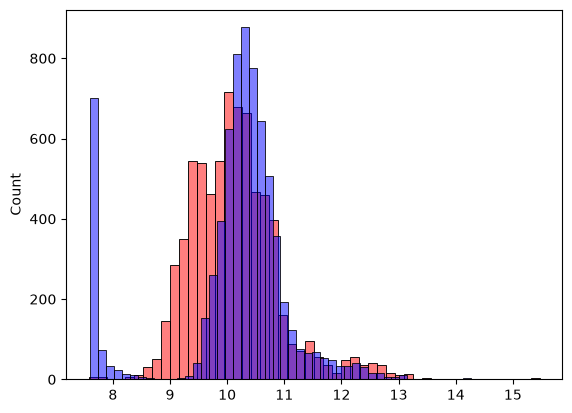

In [68]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

Now calculate the RMSE. Objection value to determine how good the model is at predicting

In [69]:
def rmse(y_train, y_pred):
    error = (y_train-y_pred) ** 2
    mse = error.mean()
    return np.sqrt(mse)

In [70]:
rmse(y_train, y_pred)

np.float64(0.7063387650493995)

Now runmodel against validaton dataset

<Axes: ylabel='Count'>

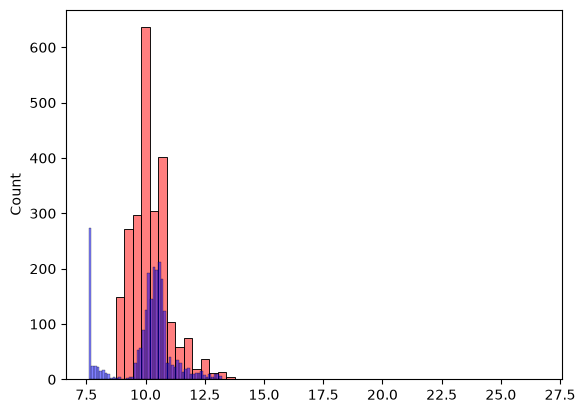

In [61]:
sns.histplot(y_pred_val, color='red', alpha=0.5, bins=50)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50)

In [60]:
X_val = df_val[base].fillna(0).values
y_pred_val = w0+X_val.dot(w)

rmse(y_val,y_pred_val)

np.float64(0.8602674179621871)